# AI & ML Internship - Task 3
## House Price Prediction using Linear Regression

This notebook demonstrates data preparation, train-test splitting, linear regression, evaluation metrics, and visualization. Because the original `house_prices.csv` file was not provided, the notebook uses clearly labelled sample data for testing.

## 1. Import Libraries and Prepare Sample Dataset

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Sample data for demonstration only; not real market data
data = pd.DataFrame({
    'square_feet': [800, 950, 1100, 1200, 1350, 1500, 1650, 1800, 2000, 2200,
                    900, 1050, 1250, 1450, 1700, 1900, 2100, 2300, 1000, 1550],
    'bedrooms':    [2, 2, 2, 3, 3, 3, 3, 4, 4, 4,
                    2, 2, 3, 3, 3, 4, 4, 4, 2, 3],
    'bathrooms':   [1, 1, 2, 2, 2, 2, 2, 3, 3, 3,
                    1, 2, 2, 2, 3, 3, 3, 4, 1, 2],
    'price':       [120000, 145000, 180000, 210000, 230000, 260000, 280000, 330000, 360000, 400000,
                    135000, 170000, 215000, 250000, 300000, 350000, 390000, 430000, 150000, 270000]
})

print('Sample dataset preview:')
display(data.head())
print('\nDataset information:')
data.info()

Sample dataset preview:


,square_feet,bedrooms,bathrooms,price
0,800,2,1,120000
1,950,2,1,145000
2,1100,2,2,180000
3,1200,3,2,210000
4,1350,3,2,230000



Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 20 entries, 0 to 19
Data columns (total 4 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   square_feet  20 non-null     int64
 1   bedrooms     20 non-null     int64
 2   bathrooms    20 non-null     int64
 3   price        20 non-null     int64
dtypes: int64(4)
memory usage: 772.0 bytes


## 2. Split Data into Training and Testing Sets

In [2]:
X = data[['square_feet', 'bedrooms', 'bathrooms']]
y = data['price']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print('Training rows:', len(X_train))
print('Testing rows:', len(X_test))

Training rows: 16
Testing rows: 4


## 3. Fit the Linear Regression Model

In [3]:
model = LinearRegression()
model.fit(X_train, y_train)

y_pred = model.predict(X_test)

print('Model trained successfully.')
print('Coefficients:', model.coef_)
print('Intercept:', model.intercept_)

Model trained successfully.
Coefficients: [  171.20583287 11832.30510376  9492.9893438 ]
Intercept: -52806.505888971384


## 4. Evaluate the Model

In [4]:
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print(f'MAE: {mae:.2f}')
print(f'MSE: {mse:.2f}')
print(f'RMSE: {rmse:.2f}')
print(f'R² Score: {r2:.4f}')

results = pd.DataFrame({'Actual Price': y_test, 'Predicted Price': y_pred})
display(results.reset_index(drop=True))

MAE: 2531.69
MSE: 7015109.67
RMSE: 2648.61
R² Score: 0.9996


,Actual Price,Predicted Price
0,120000,117315.759955
1,430000,426268.087493
2,350000,348292.765003
3,145000,142996.634885


## 5. Visualize Actual and Predicted Prices

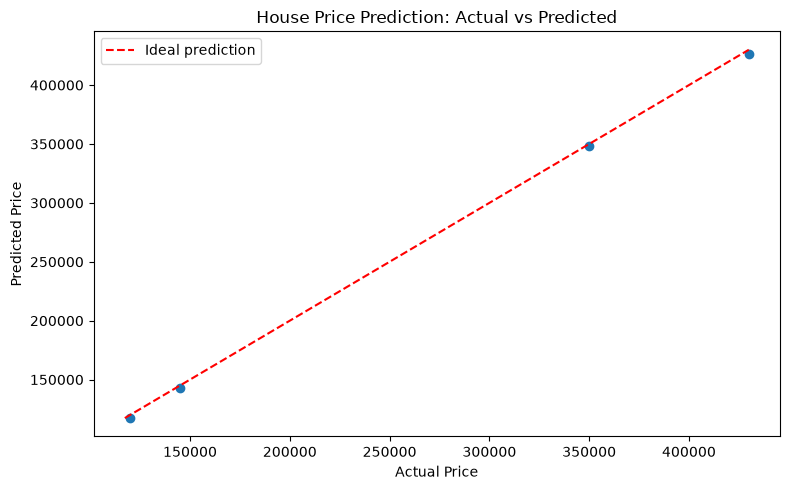

In [5]:
plt.figure(figsize=(8, 5))
plt.scatter(y_test, y_pred)
lower = min(y_test.min(), y_pred.min())
upper = max(y_test.max(), y_pred.max())
plt.plot([lower, upper], [lower, upper], 'r--', label='Ideal prediction')
plt.xlabel('Actual Price')
plt.ylabel('Predicted Price')
plt.title('House Price Prediction: Actual vs Predicted')
plt.legend()
plt.tight_layout()
plt.show()

## Conclusion

The linear regression model was trained and evaluated using sample data. For a real house-price prediction task, replace the sample DataFrame with your actual `house_prices.csv` dataset and confirm that it contains `square_feet`, `bedrooms`, `bathrooms`, and `price` columns.